# Double wishbone suspension kinematics

The example is the front view of a Formula Student double wishbone suspension at the right front wheel, as a digital
mock-up, with the car's center line at x = 0, the ground at y = 0 and lengths in mm. The body stays in place while the
wheel moves through bump and rebound. Two setups are compared side by side: A with a short swing arm and a pushrod
from the lower wishbone up to the rocker, and B with nearly parallel wishbones and a pullrod from the upper wishbone
down to a rocker low in the body. Every position is a chain of circle intersections. The extended wishbones meet in
the instant center, and the line from the tire's contact patch through it crosses the center line at the roll
center. The rod's change in length over the wheel's travel is the motion ratio that the spring and damper see.

![Two double wishbone suspensions moving through bump and rebound](../_static/gallery/suspension-kinematics.gif){.result}

In [1]:
import math
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import planex as px

## The two setups

The wheel center `WC` is at (600, 230) and the contact patch `CP` right below it, at (600, 0). The tire is drawn as
its front view, 180 wide and 460 high. Each setup is given by its hardpoints:

- `UI` and `LI`, the inner pivots of the upper and the lower wishbone on the body;
- `UO` and `LO`, the outer ball joints on the upright;
- `mount`, where the rod sits on its wishbone, and `body`, its other end at the rocker.

In [2]:
WC = (600.0, 230.0)
CP = (600.0, 0.0)
tire = px.QuickSketch((510, 0)).Rectangle(180, 460).Face()
setups = {
    "A: short swing arm, pushrod": {"UI": (300.0, 290.0), "UO": (575.0, 335.0),
                                    "LI": (220.0, 120.0), "LO": (585.0, 130.0),
                                    "rod": "lower", "mount": (540.0, 150.0),
                                    "body": (240.0, 470.0), "push": True},
    "B: long swing arm, pullrod": {"UI": (300.0, 300.0), "UO": (575.0, 319.25),
                                   "LI": (220.0, 112.0), "LO": (585.0, 119.3),
                                   "rod": "upper", "mount": (530.0, 316.0),
                                   "body": (270.0, 100.0), "push": False},
}

Their link lengths in mm:

In [3]:
for name, S in setups.items():
    links = {"upper wishbone": ("UI", "UO"), "lower": ("LI", "LO"), "upright": ("UO", "LO"), "rod": ("mount", "body")}
    print(name, {link: round(math.dist(S[a], S[b]), 1) for link, (a, b) in links.items()})

A: short swing arm, pushrod {'upper wishbone': 278.7, 'lower': 365.1, 'upright': 205.2, 'rod': 438.6}
B: long swing arm, pullrod {'upper wishbone': 275.7, 'lower': 365.1, 'upright': 200.2, 'rod': 338.0}


## Instant center and roll center

Each wishbone's line is extended far inboard, and where the two cross is the instant center, the point about which
the wheel turns for small motions. The line from the contact patch through it crosses the center line at the roll
center. `extended` draws a line 50 m long from a ball joint through the inner pivot.

In [4]:
def extended(p, q, length=50000.0):
    d = math.dist(p, q)
    return px.Line(p, (p[0] + (q[0] - p[0]) / d * length, p[1] + (q[1] - p[1]) / d * length))


def centers(S, uo, lo, cp):
    ic = extended(uo, S["UI"]).Intersections(extended(lo, S["LI"]))[0]
    rc = extended(cp, (ic.x, ic.y)).Intersections(px.Line((0, -500), (0, 1000)))[0]
    return (ic.x, ic.y), (rc.x, rc.y)

**Check:** the same points follow from the formula for the crossing of two lines through two points each. The
swing arm is the distance from the contact patch to the instant center:

In [5]:
def crossing(p1, p2, p3, p4):
    d = (p1[0] - p2[0]) * (p3[1] - p4[1]) - (p1[1] - p2[1]) * (p3[0] - p4[0])
    a, b = p1[0] * p2[1] - p1[1] * p2[0], p3[0] * p4[1] - p3[1] * p4[0]
    return ((a * (p3[0] - p4[0]) - (p1[0] - p2[0]) * b) / d, (a * (p3[1] - p4[1]) - (p1[1] - p2[1]) * b) / d)


for name, S in setups.items():
    ic, rc = centers(S, S["UO"], S["LO"], CP)
    exact = crossing(S["UI"], S["UO"], S["LI"], S["LO"])
    print(name)
    print("  instant center", ic, "formula", exact, "swing arm", round(math.dist(ic, CP)))
    print("  roll center height", rc[1], "formula", crossing(CP, exact, (0, 0), (0, 1))[1])

A: short swing arm, pushrod
  instant center (-931.7184643510054, 88.44606946983546) formula (-931.7184643510055, 88.44606946983546) swing arm 1534
  roll center height 34.645819657456585 formula 34.645819657456585
B: long swing arm, pullrod
  instant center (-3427.9999999999986, 39.04000000000008) formula (-3427.9999999999995, 39.04000000000004) swing arm 4028
  roll center height 5.815292949354532 formula 5.815292949354525


## Moving the wheel

The lower wishbone turns about its inner pivot, and the upper ball joint is where the upper wishbone's circle meets
the upright's circle around the lower ball joint. The upright, the wheel and the contact patch move with it as one
body, and the rod's mount moves with its wishbone. Camber is the upright's rotation, negative when the top of the
wheel leans in, and rod travel is positive when the spring is compressed.

`meet` intersects two circles, `turned` turns a point about a center, and `position` returns everything for a given
angle of the lower wishbone:

In [6]:
def meet(p, r, q, s):
    return [(v.x, v.y) for v in px.Circle(p, r).Intersections(px.Circle(q, s))]


def turned(point, center, angle):
    c, s = math.cos(angle), math.sin(angle)
    x, y = point[0] - center[0], point[1] - center[1]
    return (center[0] + c * x - s * y, center[1] + s * x + c * y)


def heading(p, q):
    return math.atan2(q[1] - p[1], q[0] - p[0])


def position(S, phi):
    lo = turned(S["LO"], S["LI"], math.radians(phi))
    joints = meet(S["UI"], math.dist(S["UI"], S["UO"]), lo, math.dist(S["UO"], S["LO"]))
    uo = min(joints, key=lambda q: math.dist(q, S["UO"]))
    tilt = heading(lo, uo) - heading(S["LO"], S["UO"])

    def carried(p):
        q = turned(p, S["LO"], tilt)
        return (q[0] - S["LO"][0] + lo[0], q[1] - S["LO"][1] + lo[1])
    if S["rod"] == "lower":
        mount = turned(S["mount"], S["LI"], math.radians(phi))
    else:
        mount = turned(S["mount"], S["UI"], heading(S["UI"], uo) - heading(S["UI"], S["UO"]))
    wc, cp = carried(WC), carried(CP)
    ic, rc = centers(S, uo, lo, cp)
    change = math.dist(mount, S["body"]) - math.dist(S["mount"], S["body"])
    return {"UO": uo, "LO": lo, "mount": mount, "WC": wc, "CP": cp, "IC": ic,
            "RC": rc, "tilt": tilt, "wheel": wc[1] - WC[1],
            "camber": -math.degrees(tilt), "rod": -change if S["push"] else change}

The lower wishbone turns from −5.5° to 5.5° in steps of 0.25°. **Check:** every link keeps its length in every
position, to rounding:

In [7]:
sweeps = {name: [position(S, phi / 4) for phi in range(-22, 23)] for name, S in setups.items()}
for name, S in setups.items():
    sweep = sweeps[name]
    worst = max(max(abs(math.dist(S["UI"], P["UO"]) - math.dist(S["UI"], S["UO"])),
                    abs(math.dist(S["LI"], P["LO"]) - math.dist(S["LI"], S["LO"])),
                    abs(math.dist(P["UO"], P["LO"]) - math.dist(S["UO"], S["LO"])))
                for P in sweep)
    print(name, "wheel travel", round(sweep[0]["wheel"], 1), "to", round(sweep[-1]["wheel"], 1), "mm,",
          "largest change of a link length", worst)

A: short swing arm, pushrod wheel travel -35.4 to 35.3 mm, largest change of a link length 1.7053025658242404e-13
B: long swing arm, pullrod wheel travel -35.1 to 35.1 mm, largest change of a link length 1.7053025658242404e-13


## Wheel travel, rod travel, camber

The charts below plot against the wheel's travel:

- the rod's travel, and its slope, which is the motion ratio;
- the camber;
- the roll center's height;
- the sideways scrub of the contact patch.

At ride height, the motion ratio and the camber gain per 10 mm of bump are:

A: short swing arm, pushrod motion ratio 0.689 camber gain -0.374 degrees per 10 mm
B: long swing arm, pullrod motion ratio 0.487 camber gain -0.142 degrees per 10 mm


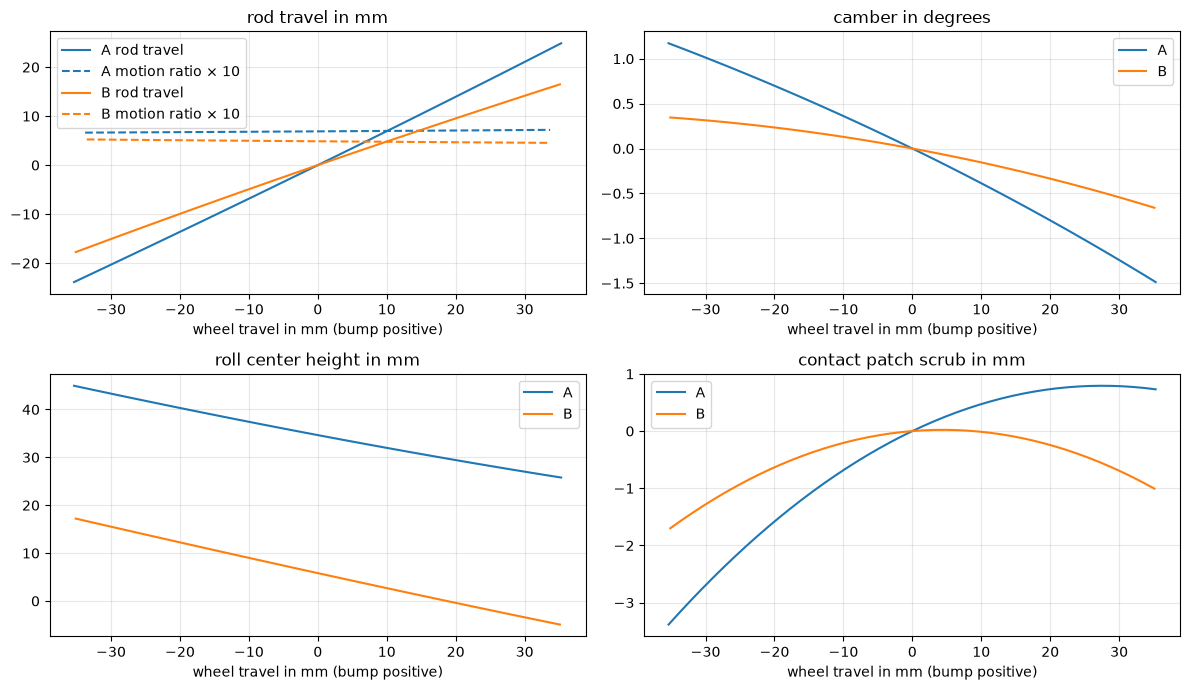

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for (name, sweep), color in zip(sweeps.items(), ("tab:blue", "tab:orange")):
    wheel = [P["wheel"] for P in sweep]
    rod = [P["rod"] for P in sweep]
    ratio = [(rod[n + 1] - rod[n - 1]) / (wheel[n + 1] - wheel[n - 1]) for n in range(1, len(sweep) - 1)]
    label = name.split(":")[0]
    axes[0, 0].plot(wheel, rod, color=color, label=f"{label} rod travel")
    axes[0, 0].plot(wheel[1:-1], [10 * q for q in ratio], "--", color=color, label=f"{label} motion ratio × 10")
    axes[0, 1].plot(wheel, [P["camber"] for P in sweep], color=color, label=label)
    axes[1, 0].plot(wheel, [P["RC"][1] for P in sweep], color=color, label=label)
    axes[1, 1].plot(wheel, [P["CP"][0] - CP[0] for P in sweep], color=color, label=label)
    middle = len(sweep) // 2
    gain = (sweep[middle + 1]["camber"] - sweep[middle - 1]["camber"]) / (wheel[middle + 1] - wheel[middle - 1]) * 10
    print(name, "motion ratio", round(ratio[middle - 1], 3), "camber gain", round(gain, 3), "degrees per 10 mm")
titles = ("rod travel in mm", "camber in degrees", "roll center height in mm", "contact patch scrub in mm")
for ax, title in zip(axes.flat, titles):
    ax.set_title(title)
    ax.set_xlabel("wheel travel in mm (bump positive)")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

## In motion

The animation runs both setups through the same lower wishbone angles, each with its numbers above it. The dashed
lines run towards the instant center, and the red dot is the roll center.

In [9]:
outline = [(x, y) for x, y in tire.ToShapely(1e-3).exterior.coords]
fig, panels = plt.subplots(1, 2, figsize=(14, 6))
drawn = []
for ax, (name, S) in zip(panels, setups.items()):
    ax.axhline(0, color="saddlebrown")
    ax.axvline(0, color="gray", lw=0.5)
    parts = {"tire": ax.fill([0], [0], color="dimgray")[0],
             "arms": ax.plot([], [], "o-", color="black", lw=2)[0],
             "rod": ax.plot([], [], "o-", color="tab:orange", lw=2)[0],
             "rays": ax.plot([], [], "--", color="tab:blue", lw=0.8)[0],
             "roll": ax.plot([], [], "o", color="tab:red")[0]}
    ax.set_xlim(-60, 720)
    ax.set_ylim(-60, 560)
    ax.set_aspect("equal")
    drawn.append((ax, name, S, parts))
order = list(range(len(sweeps[next(iter(sweeps))])))
order = order + order[::-1]

def frame(k):
    for ax, name, S, parts in drawn:
        P = sweeps[name][order[k]]
        c, s = math.cos(P["tilt"]), math.sin(P["tilt"])
        lo = S["LO"]
        parts["tire"].set_xy([(P["LO"][0] + c * (x - lo[0]) - s * (y - lo[1]),
                               P["LO"][1] + s * (x - lo[0]) + c * (y - lo[1])) for x, y in outline])
        parts["arms"].set_data([S["UI"][0], P["UO"][0], P["LO"][0], S["LI"][0]],
                               [S["UI"][1], P["UO"][1], P["LO"][1], S["LI"][1]])
        parts["rod"].set_data([P["mount"][0], S["body"][0]], [P["mount"][1], S["body"][1]])
        parts["rays"].set_data([P["UO"][0], P["IC"][0], P["LO"][0], None, P["CP"][0], P["IC"][0]],
                               [P["UO"][1], P["IC"][1], P["LO"][1], None, P["CP"][1], P["IC"][1]])
        parts["roll"].set_data([P["RC"][0]], [P["RC"][1]])
        ax.set_title(f"{name}\nwheel {P['wheel']:+.1f} mm, camber {P['camber']:+.2f}°, rod {P['rod']:+.1f} mm, "
                     f"roll center {P['RC'][1]:.1f} mm", fontsize=10)
    return [p for ax, name, S, parts in drawn for p in parts.values()]

animation = FuncAnimation(fig, frame, frames=len(order), interval=60)
plt.close(fig)
HTML(animation.to_jshtml())

In [10]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_animation(animation, "suspension-kinematics", dpi=80, bare=True, panels=[0])